# OLIST DELIVERY TIME PREDICTION - MACHINE LEARNING

## Import Library

In [28]:
import pandas as pd
import os
from dotenv import load_dotenv
from tqdm import tqdm
import re
import duckdb
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import warnings

from statsmodels.tools.tools import add_constant
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split, cross_validate, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
import category_encoders as ce
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, GradientBoostingRegressor, AdaBoostRegressor, BaggingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import fbeta_score, make_scorer

import pickle

In [29]:
duckdb.sql("LOAD SPATIAL;")

## Import Data

In [30]:
dataset = {
    'customers_df'              : 'olist_customers_dataset',
    'geolocation_df'            : 'olist_geolocation_dataset',
    'items_df'                  : 'olist_order_items_dataset',
    'payments_df'               : 'olist_order_payments_dataset',
    'reviews_df'                : 'olist_order_reviews_dataset',
    'orders_df'                 : 'olist_orders_dataset',
    'products_df'               : 'olist_products_dataset',
    'sellers_df'                : 'olist_sellers_dataset',
    'products_category_df'      : 'product_category_name_translation'
}

load_dotenv() 

dfs = {}
for df_name, df in tqdm(dataset.items(), total=len(dataset), desc='Import Data: '):
    dfs[df_name] = pd.read_csv(f"{os.getenv('data_path')}/{df}.csv")

globals().update(dfs)

Import Data: 100%|██████████| 9/9 [00:01<00:00,  7.02it/s]


## Data Cleaning

In [31]:
df_list = []
for i in dfs.keys():
    dataframe_obj = globals()[i] 
    df_list.append(dataframe_obj)

In [32]:
def convert_timestamp(df):
    for i in df.columns:
        if re.search(r'timestamp|_at|_date', i, flags=re.IGNORECASE):
            df[i] = df[i].astype('timestamp[s][pyarrow]')


for i in df_list:
    convert_timestamp(i)

In [33]:
products_df_group = products_df['product_category_name'].value_counts(dropna=False).reset_index()
products_group_english_df = products_df_group.merge(products_category_df, on='product_category_name', how='left')
products_group_english_df = products_group_english_df[['product_category_name', 'product_category_name_english', 'count']]
missing_product_english = products_group_english_df[products_group_english_df['product_category_name_english'].isna()][['product_category_name']].dropna()
missing_product_english['product_category_name_english'] = ['kitchen_appliances_and_food_prep', 'pc_games']
products_category_df = pd.concat([products_category_df, missing_product_english])
products_category_df

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor
...,...,...
68,fraldas_higiene,diapers_and_hygiene
69,fashion_roupa_infanto_juvenil,fashion_childrens_clothes
70,seguros_e_servicos,security_and_services
66,portateis_cozinha_e_preparadores_de_alimentos,kitchen_appliances_and_food_prep


In [34]:
dfs_dict = {
    'geolocation': geolocation_df, 
    'reviews': reviews_df, 
    'products': products_df
}

for name, df in dfs_dict.items():
    if name != 'products':
        df.drop_duplicates(inplace=True)
    else:
        df.dropna(inplace=True)

In [35]:
query = """
SELECT
    geolocation_zip_code_prefix,
    geolocation_city,
    geolocation_state,
    ST_Point(geolocation_lng, geolocation_lat) AS geometry
FROM
    geolocation_df
ORDER BY 1
"""

geolocation_db = duckdb.sql(query)
geolocation_db

┌─────────────────────────────┬──────────────────┬───────────────────┬────────────────────────────────────────────────┐
│ geolocation_zip_code_prefix │ geolocation_city │ geolocation_state │                    geometry                    │
│            int64            │     varchar      │      varchar      │                    geometry                    │
├─────────────────────────────┼──────────────────┼───────────────────┼────────────────────────────────────────────────┤
│                        1001 │ são paulo        │ SP                │ POINT (-46.6339571183853 -23.549779299469115)  │
│                        1001 │ sao paulo        │ SP                │ POINT (-46.63396956010149 -23.5498252739339)   │
│                        1001 │ são paulo        │ SP                │ POINT (-46.63402708563671 -23.549951273933896) │
│                        1001 │ sao paulo        │ SP                │ POINT (-46.63433817805407 -23.55049770690751)  │
│                        1001 │ sao paul

In [36]:
query = f"""
SELECT
    * EXCLUDE(geom),
    ST_GeomFromText(ST_AsText(geom)) AS geometry
FROM
    ST_Read('{os.getenv('data_path_geo')}/geoBoundaries-BRA-ADM0.geojson')
"""

brazil_boundary = duckdb.sql(query)
brazil_boundary

┌─────────┬───────────┬──────────┬─────────────────────────┬────────────┬───────────┬───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

In [37]:
query = """
SELECT
    a.geolocation_zip_code_prefix,
    a.geolocation_city,
    a.geolocation_state,
    ST_Y(a.geometry) AS latitude,
    ST_X(a.geometry) AS longitude
FROM
    geolocation_db AS a
INNER JOIN
    brazil_boundary AS b
ON
    ST_Within(a.geometry, b.geometry)
"""

geolocation_clean_db = duckdb.sql(query)
geolocation_clean_db

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌─────────────────────────────┬──────────────────┬───────────────────┬─────────────────────┬─────────────────────┐
│ geolocation_zip_code_prefix │ geolocation_city │ geolocation_state │      latitude       │      longitude      │
│            int64            │     varchar      │      varchar      │       double        │       double        │
├─────────────────────────────┼──────────────────┼───────────────────┼─────────────────────┼─────────────────────┤
│                        1001 │ são paulo        │ SP                │ -23.549779299469115 │   -46.6339571183853 │
│                        1001 │ sao paulo        │ SP                │   -23.5498252739339 │  -46.63396956010149 │
│                        1001 │ são paulo        │ SP                │ -23.549951273933896 │  -46.63402708563671 │
│                        1001 │ sao paulo        │ SP                │  -23.55049770690751 │  -46.63433817805407 │
│                        1001 │ sao paulo        │ SP                │ -23.55142

In [38]:
query = """
SELECT
    geolocation_zip_code_prefix,
    MEDIAN(latitude) AS geolocation_lat,
    MEDIAN(longitude) AS geolocation_lng,
    MODE(strip_accents(geolocation_city)) AS geolocation_city,
    MODE(geolocation_state) AS geolocation_state
FROM
    geolocation_clean_db
GROUP BY 1
ORDER BY 1 ASC
"""

geolocation_df = duckdb.sql(query).to_df()
geolocation_df

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1001,-23.549951,-46.634027,sao paulo,SP
1,1002,-23.548228,-46.635247,sao paulo,SP
2,1003,-23.548977,-46.635313,sao paulo,SP
3,1004,-23.549550,-46.634771,sao paulo,SP
4,1005,-23.549763,-46.636100,sao paulo,SP
...,...,...,...,...,...
19006,99960,-27.953797,-52.029641,charrua,RS
19007,99965,-28.179542,-52.035551,agua santa,RS
19008,99970,-28.343257,-51.875470,ciriaco,RS
19009,99980,-28.388342,-51.846871,david canabarro,RS


In [39]:
customers_df = customers_df.drop(columns=['customer_city', 'customer_state'])
sellers_df = sellers_df.drop(columns=['seller_city', 'seller_state'])

In [40]:
dataset_clean = {
    'customers_df'              : customers_df,
    'geolocation_df'            : geolocation_df,
    'items_df'                  : items_df,
    'payments_df'               : payments_df,
    'reviews_df'                : reviews_df,
    'orders_df'                 : orders_df,
    'products_df'               : products_df,
    'sellers_df'                : sellers_df,
    'products_category_df'      : products_category_df
}

for key,value in dataset_clean.items():
    print(f"{key}: {value.shape}")

customers_df: (99441, 3)
geolocation_df: (19011, 5)
items_df: (112650, 7)
payments_df: (103886, 5)
reviews_df: (99224, 7)
orders_df: (99441, 8)
products_df: (32340, 9)
sellers_df: (3095, 2)
products_category_df: (73, 2)


## Features Creation

In [41]:
query = """
WITH selected_data AS (
SELECT
    *,
    date_diff('second', order_purchase_timestamp, order_approved_at) AS approved_time_s,
    date_diff('second', order_approved_at, order_delivered_carrier_date) AS delivered_carrier_time_s,
    date_diff('second', order_delivered_carrier_date, order_delivered_customer_date) AS delivered_customer_time_s,
    date_diff('second', order_purchase_timestamp, order_delivered_customer_date) AS total_delivery_time_s,
    date_diff('second', order_purchase_timestamp, order_estimated_delivery_date) AS total_estimated_time_s,
    CASE
        WHEN order_delivered_customer_date > order_estimated_delivery_date THEN TRUE
        ELSE FALSE
    END AS is_late
FROM
    orders_df
WHERE
    order_delivered_customer_date IS NOT NULL
    AND order_status = 'delivered'
)
SELECT
    *
FROM
    selected_data
WHERE
    approved_time_s > 0  AND delivered_carrier_time_s > 0 AND delivered_customer_time_s > 0
ORDER BY total_delivery_time_s ASC
"""

orders_details_df = duckdb.sql(query).to_df()
orders_details_df

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,approved_time_s,delivered_carrier_time_s,delivered_customer_time_s,total_delivery_time_s,total_estimated_time_s,is_late
0,1d893dd7ca5f77ebf5f59f0d2017eee0,b19da0df0271e8a3553e3670f86aeab5,delivered,2017-06-19 08:19:45,2017-06-19 08:30:20,2017-06-19 13:32:04,2017-06-19 21:07:52,2017-06-30,635,18104,27348,46087,920415,False
1,434cecee7d1a65fc65358a632b6f725f,922a46283625e9c096bfd998913c470c,delivered,2017-05-29 13:21:46,2017-05-29 13:30:24,2017-05-29 14:54:51,2017-05-30 08:06:56,2017-06-19,518,5067,61925,67510,1766294,False
2,f3c6775ba3d2d9fe2826f93b71f12008,6aef84c09844a371d82a49152c550b95,delivered,2017-07-04 11:37:47,2017-07-04 11:50:21,2017-07-04 13:53:13,2017-07-05 08:09:26,2017-07-17,754,7372,65773,73899,1081333,False
3,8339b608be0d84fca9d8da68b58332c3,ff58662c328f81d3ee549c9caa942f39,delivered,2018-06-26 20:48:33,2018-06-26 21:07:25,2018-06-27 11:31:00,2018-06-27 17:31:53,2018-07-25,1132,51815,21653,74600,2430687,False
4,bb5a519e352b45b714192a02ffe25681,118295a853acb536efff13740faf5be8,delivered,2017-05-31 11:11:55,2017-05-31 11:22:55,2017-05-31 11:36:15,2017-06-01 08:34:36,2017-06-27,660,800,75501,76961,2292485,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
93825,6e82dcfb5eada6283dba34f164e636f5,59b42de1617fdda0b327375d35efd708,delivered,2017-05-17 19:09:02,2017-05-18 19:22:29,2017-05-19 10:57:36,2017-11-16 10:56:45,2017-06-14,87207,56107,15638349,15781663,2350258,True
93826,47b40429ed8cce3aee9199792275433f,cb2caaaead400c97350c37a3fc536867,delivered,2018-01-03 09:44:01,2018-01-03 10:31:15,2018-02-06 01:48:28,2018-07-13 20:51:31,2018-01-19,2834,2906233,13633383,16542450,1347359,True
93827,440d0d17af552815d15a9e41abe49359,7815125148cfa1e8c7fee1ff7974f16c,delivered,2017-03-07 23:59:51,2017-03-09 01:11:33,2017-03-15 13:00:08,2017-09-19 15:12:50,2017-04-07,90702,560915,16251162,16902779,2592009,True
93828,1b3190b2dfa9d789e1f14c05b647a14a,d306426abe5fca15e54b645e4462dc7b,delivered,2018-02-23 14:57:35,2018-02-23 15:16:14,2018-02-26 18:49:07,2018-09-19 23:24:07,2018-03-15,1119,271973,17728500,18001592,1674145,True


In [42]:
query = """
WITH agg_data AS (
SELECT
    o.order_id,
    o.order_purchase_timestamp,
    s.seller_id,
    COUNT(DISTINCT o.order_id) AS seller_total_order,
    AVG(r.review_score) AS seller_avg_review_score,
    AVG(o.approved_time_s) AS seller_avg_approved_time_s,
    AVG(o.delivered_carrier_time_s) AS seller_avg_delivered_carrier_time_s,
    AVG(o.delivered_customer_time_s) AS seller_avg_delivered_customer_time_s,
    AVG(o.total_delivery_time_s) AS seller_avg_total_delivery_time_s,
    ROUND(COUNT(DISTINCT CASE WHEN o.is_late = TRUE THEN o.order_id END) / COUNT(DISTINCT o.order_id) * 100, 3) AS seller_late_rate
FROM
    sellers_df AS s
INNER JOIN
    items_df AS i
ON
    s.seller_id = i.seller_id
LEFT JOIN
    reviews_df AS r
ON
    i.order_id = r.order_id
INNER JOIN
    orders_details_df AS o
ON
    i.order_id = o.order_id
GROUP BY ALL
)

, window_data AS (
SELECT
    order_id,
    order_purchase_timestamp,
    seller_id,
    COALESCE(SUM(seller_total_order) OVER w, 0) AS seller_hist_total_order,
    AVG(seller_avg_review_score) OVER w AS seller_hist_avg_review_score,
    AVG(seller_avg_approved_time_s) OVER w AS seller_hist_avg_approved_time_s,
    AVG(seller_avg_delivered_carrier_time_s) OVER w AS seller_hist_avg_delivered_carrier_time_s,
    AVG(seller_avg_delivered_customer_time_s) OVER w AS seller_hist_avg_delivered_customer_time_s,
    AVG(seller_avg_total_delivery_time_s) OVER w AS seller_hist_avg_total_delivery_time_s,
    AVG(seller_late_rate) OVER w AS seller_hist_late_rate
FROM
    agg_data
WINDOW w AS (
    PARTITION BY seller_id 
    ORDER BY order_purchase_timestamp, order_id 
    ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING
)
)

SELECT
    order_id,
    AVG(seller_hist_total_order) AS avg_seller_hist_total_order,
    AVG(seller_hist_avg_review_score) AS seller_hist_avg_review_score,
    AVG(seller_hist_avg_approved_time_s) AS seller_hist_avg_approved_time_s,
    AVG(seller_hist_avg_delivered_carrier_time_s) AS seller_hist_avg_delivered_carrier_time_s,
    AVG(seller_hist_avg_delivered_customer_time_s) AS seller_hist_avg_delivered_customer_time_s,
    AVG(seller_hist_avg_total_delivery_time_s) AS seller_hist_avg_total_delivery_time_s,
    AVG(seller_hist_late_rate) AS avg_seller_hist_late_rate
FROM
    window_data
GROUP BY order_id
"""

seller_features_df = duckdb.sql(query).to_df()
seller_features_df

,order_id,avg_seller_hist_total_order,seller_hist_avg_review_score,seller_hist_avg_approved_time_s,seller_hist_avg_delivered_carrier_time_s,seller_hist_avg_delivered_customer_time_s,seller_hist_avg_total_delivery_time_s,avg_seller_hist_late_rate
0,83c3c5d85ecc80dc98b322dc63c47cf2,72.0,4.347222,27942.305556,265064.541667,6.115287e+05,9.045355e+05,2.777778
1,e126a4c926bda89ae444a788cb74d989,146.0,4.201291,41540.142995,262104.548394,6.977307e+05,1.001375e+06,4.075021
2,8925dc5eb0b5639ea6e3f962108d6207,92.0,4.239130,27526.684783,275440.652174,6.089844e+05,9.119517e+05,4.347826
3,6fed61864e73f5457549fa69ad7c88a2,100.0,4.230000,26665.630000,274455.070000,6.237864e+05,9.249071e+05,4.000000
4,864fb7308cf63ed5141c340f258de1b5,102.0,4.245098,26161.431373,272598.911765,6.227384e+05,9.214987e+05,3.921569
...,...,...,...,...,...,...,...,...
93825,816981834423576036dbac9e4ccf94ad,48.0,4.437500,26459.166667,283817.229167,6.023172e+05,9.125936e+05,4.166667
93826,59162d0a7fe62c725ed7be7259ae3224,1.0,5.000000,895.000000,258262.000000,7.747170e+05,1.033874e+06,0.000000
93827,b1e7caa2d22ccc061ebfed60acc21b34,4.0,4.500000,57121.750000,155972.000000,1.136942e+06,1.350036e+06,0.000000
93828,a997ce452b12e113ccd903fd9323d382,4.0,4.500000,164737.500000,195828.000000,1.384282e+06,1.744848e+06,0.000000


In [43]:
query = """
WITH data_prep AS (
SELECT DISTINCT
    o.order_id,
    o.order_status,
    o.customer_id,
    o.order_purchase_timestamp,
    dayofweek(o.order_purchase_timestamp) AS purchase_dayofweek,
    hour(o.order_purchase_timestamp) AS purchase_hour,
    o.order_approved_at,
    o.order_delivered_carrier_date,
    o.order_delivered_customer_date,
    o.approved_time_s,
    o.delivered_carrier_time_s,
    o.delivered_customer_time_s,
    o.total_delivery_time_s,
    o.total_estimated_time_s,
    o.is_late,
    
    gc.geolocation_city AS customer_city,
    gc.geolocation_state AS customer_state,
    gc.geolocation_lat AS customer_latitude,
    gc.geolocation_lng AS customer_longitude,

    p.product_weight_g,
    p.product_length_cm,
    p.product_height_cm,
    p.product_width_cm,
    pc.product_category_name_english,

    i.order_item_id,
    i.product_id,
    i.price,
    i.freight_value,

    gs.geolocation_city AS seller_city,
    gs.geolocation_state AS seller_state,
    gs.geolocation_lat AS seller_latitude,
    gs.geolocation_lng AS seller_longitude,

    ps.payment_type,

    s.seller_id,
    r.review_score
FROM
    orders_details_df AS o
INNER JOIN
    customers_df AS c
ON
    o.customer_id = c.customer_id
INNER JOIN
    geolocation_df AS gc
ON
    gc.geolocation_zip_code_prefix = c.customer_zip_code_prefix
INNER JOIN
    items_df AS i
ON
    i.order_id = o.order_id
INNER JOIN
    products_df AS p
ON
    i.product_id = p.product_id
INNER JOIN
    products_category_df AS pc
ON
    pc.product_category_name = p.product_category_name
INNER JOIN
    sellers_df AS s
ON
    s.seller_id = i.seller_id
INNER JOIN
    geolocation_df AS gs
ON
    gs.geolocation_zip_code_prefix = s.seller_zip_code_prefix
INNER JOIN
    payments_df AS ps
ON
    o.order_id = ps.order_id
LEFT JOIN
    reviews_df AS r
ON
    i.order_id = r.order_id

)

, agg_data AS (
SELECT
    order_id,
    order_status,
    customer_id,
    order_purchase_timestamp,
    purchase_dayofweek,
    purchase_hour,
    CASE
        WHEN purchase_dayofweek IN (0,6) THEN TRUE
        ELSE FALSE
    END AS is_purchase_on_weekend,
    order_approved_at,
    order_delivered_carrier_date,
    order_delivered_customer_date,
    approved_time_s,
    delivered_carrier_time_s,
    delivered_customer_time_s,
    total_delivery_time_s,
    total_estimated_time_s,

    customer_city,
    customer_state,
    customer_latitude,
    customer_longitude,
    COUNT(DISTINCT seller_id) AS total_seller_id,
    AVG(review_score) AS seller_avg_review_score,
    MODE(seller_city) AS mode_seller_city,
    MODE(seller_state) AS mode_seller_state,
    MODE(seller_latitude) AS mode_seller_latitude,
    MODE(seller_longitude) AS mode_seller_longitude,
    MODE(product_category_name_english) AS mode_product_category_name_english,
    SUM(product_weight_g) AS total_weight_g,
    SUM((product_length_cm * product_height_cm * product_width_cm)) AS total_volume_cm3,
    MAX(order_item_id) AS total_items,
    COUNT(DISTINCT product_id) AS total_unique_products,
    SUM(price) AS total_price,
    SUM(freight_value) AS freight_value,
    (SUM(freight_value) / SUM(price)) AS freight_ratio,

    COUNT(CASE WHEN payment_type = 'credit_card' THEN order_id END) AS payment_installments,
    MODE(payment_type) AS mode_payment_type,
    COUNT(DISTINCT payment_type) AS total_payment_type,
    BOOL_OR(payment_type = 'voucher') AS is_using_voucher,
    BOOL_OR(payment_type = 'boleto') AS is_using_boleto
FROM
    data_prep
GROUP BY ALL
)

SELECT
    a.order_id,
    total_delivery_time_s,
    total_estimated_time_s,
    a.* EXCLUDE(a.order_id, total_delivery_time_s, total_estimated_time_s, customer_id, order_purchase_timestamp, order_approved_at, order_delivered_carrier_date, order_delivered_customer_date, approved_time_s, delivered_carrier_time_s, delivered_customer_time_s, customer_latitude, customer_longitude, mode_seller_latitude, mode_seller_longitude),
    (total_weight_g / total_volume_cm3) AS product_density,
    ROUND(ST_Distance_Spheroid(ST_Point(customer_latitude, customer_longitude), ST_Point(mode_seller_latitude, mode_seller_longitude)), 3) AS distance_m,
    IF(LOWER(CONCAT(customer_state, ' - ', customer_city)) = LOWER(CONCAT(mode_seller_state, ' - ', mode_seller_city)), TRUE, FALSE) AS is_same_city,
    IF(LOWER(customer_state) = LOWER(mode_seller_state), TRUE, FALSE) AS is_same_state,
    CASE
        WHEN LOWER(CONCAT(customer_state, ' - ', customer_city))
        IN (
            'ac - rio branco',     'al - maceio',      'ap - macapa',
            'am - manaus',         'ba - salvador',    'ce - fortaleza',
            'df - brasilia',       'es - vitoria',     'go - goiania',
            'ma - sao luis',       'mt - cuiaba',      'ms - campo grande',
            'mg - belo horizonte', 'pa - belem',       'pb - joao pessoa',
            'pr - curitiba',       'pe - recife',      'pi - teresina',
            'rj - rio de janeiro', 'rn - natal',       'rs - porto alegre',
            'ro - porto velho',    'rr - boa vista',   'sc - florianopolis',
            'sp - sao paulo',      'se - aracaju',     'to - palmas'
        ) THEN TRUE
        ELSE FALSE
    END AS is_customer_capital_city,
    CASE
        WHEN LOWER(CONCAT(mode_seller_state, ' - ', mode_seller_city))
        IN (
            'ac - rio branco',     'al - maceio',      'ap - macapa',
            'am - manaus',         'ba - salvador',    'ce - fortaleza',
            'df - brasilia',       'es - vitoria',     'go - goiania',
            'ma - sao luis',       'mt - cuiaba',      'ms - campo grande',
            'mg - belo horizonte', 'pa - belem',       'pb - joao pessoa',
            'pr - curitiba',       'pe - recife',      'pi - teresina',
            'rj - rio de janeiro', 'rn - natal',       'rs - porto alegre',
            'ro - porto velho',    'rr - boa vista',   'sc - florianopolis',
            'sp - sao paulo',      'se - aracaju',     'to - palmas'
        ) THEN TRUE
        ELSE FALSE
    END AS is_seller_capital_city,
    sf.* EXCLUDE(order_id)
FROM
    agg_data AS a
INNER JOIN
    seller_features_df AS sf
ON
    a.order_id = sf.order_id
;
"""

delivery_time_estimation_df = duckdb.sql(query).to_df()
delivery_time_estimation_df

,order_id,total_delivery_time_s,total_estimated_time_s,order_status,purchase_dayofweek,purchase_hour,is_purchase_on_weekend,customer_city,customer_state,total_seller_id,...,is_same_state,is_customer_capital_city,is_seller_capital_city,avg_seller_hist_total_order,seller_hist_avg_review_score,seller_hist_avg_approved_time_s,seller_hist_avg_delivered_carrier_time_s,seller_hist_avg_delivered_customer_time_s,seller_hist_avg_total_delivery_time_s,avg_seller_hist_late_rate
0,2de6a73b60b6fb18004ea51e46bebc1d,153468,858138,delivered,1,1,False,jacarei,SP,1,...,True,False,False,1030.0,4.143415,37739.583495,196141.023301,8.140858e+05,1.047966e+06,7.961165
1,782af21dd678b879fae4f0f0d80bfda9,167735,356054,delivered,3,21,False,sao paulo,SP,1,...,True,True,True,1632.0,3.976558,32990.322917,109624.320466,7.093702e+05,8.519849e+05,6.372549
2,884cb4ce4a06390d35206de06f785d13,170712,789345,delivered,2,20,False,sao paulo,SP,1,...,True,True,True,129.0,4.242188,36943.217054,127811.232558,7.819479e+05,9.467023e+05,9.302326
3,5471d5c0cbff5d04724a56e49cd4d308,171215,1922765,delivered,3,17,False,rio de janeiro,RJ,1,...,True,True,True,46.0,3.977778,25312.086957,147291.152174,1.114032e+06,1.286636e+06,15.217391
4,2680d53d669b7bcd1cfde553ffa78aba,176339,189316,delivered,2,19,False,sao paulo,SP,1,...,True,True,True,1217.0,4.200165,41846.002465,150853.996713,7.502082e+05,9.429082e+05,8.052588
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
92067,dc39d8fbbdc748fe466dd8af6bec5b6d,2123908,1953336,delivered,2,9,False,belo horizonte,MG,1,...,False,True,True,449.0,4.033632,45003.634744,282562.391982,8.519193e+05,1.179485e+06,8.685969
92068,e8295bee3fcc58cbd94f165f36c11f4b,2129658,2152236,delivered,5,2,False,petropolis,RJ,1,...,False,False,False,32.0,3.875000,10161.437500,243340.093750,1.057291e+06,1.310793e+06,15.625000
92069,3a8d1da60e589d438a1517f54f3e5f9e,2895003,2200256,delivered,0,12,True,salvador,BA,1,...,False,True,False,257.0,4.035433,40080.918288,306270.264591,8.893539e+05,1.235705e+06,7.003891
92070,e677b67c28dfc75969bbf0ff515c0983,3919682,3238381,delivered,6,12,True,teresina,PI,1,...,False,True,False,843.0,3.461310,45275.386714,950538.736655,9.265535e+05,1.922368e+06,9.964413


In [44]:
cols = ['purchase_dayofweek', 'purchase_hour', 'is_purchase_on_weekend', 'is_using_voucher', 'is_using_boleto', 'total_seller_id', 'is_same_city', 'is_same_state', 'is_customer_capital_city', 'is_seller_capital_city', 'total_payment_type']
delivery_time_estimation_df = delivery_time_estimation_df.astype({c: str for c in cols})
delivery_time_estimation_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 92072 entries, 0 to 92071
Data columns (total 39 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   order_id                                   92072 non-null  str    
 1   total_delivery_time_s                      92072 non-null  int64  
 2   total_estimated_time_s                     92072 non-null  int64  
 3   order_status                               92072 non-null  str    
 4   purchase_dayofweek                         92072 non-null  str    
 5   purchase_hour                              92072 non-null  str    
 6   is_purchase_on_weekend                     92072 non-null  str    
 7   customer_city                              92072 non-null  str    
 8   customer_state                             92072 non-null  str    
 9   total_seller_id                            92072 non-null  str    
 10  seller_avg_review_score          

## Exploratory Data Analysis

### Numerical Feature

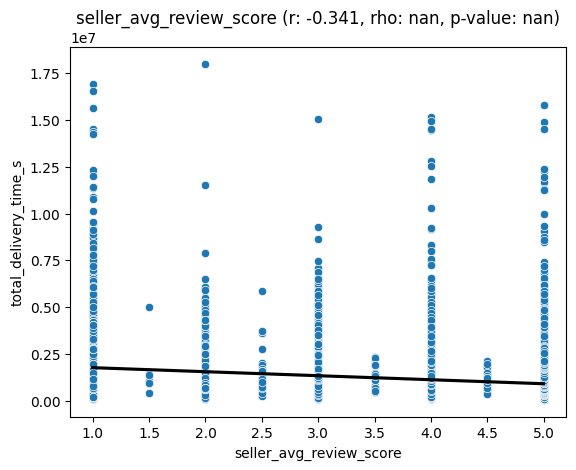

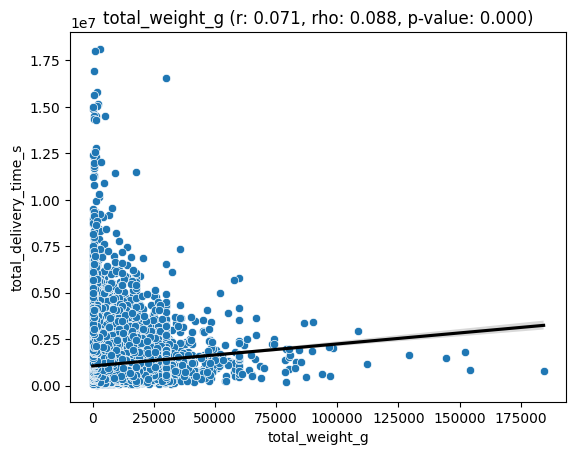

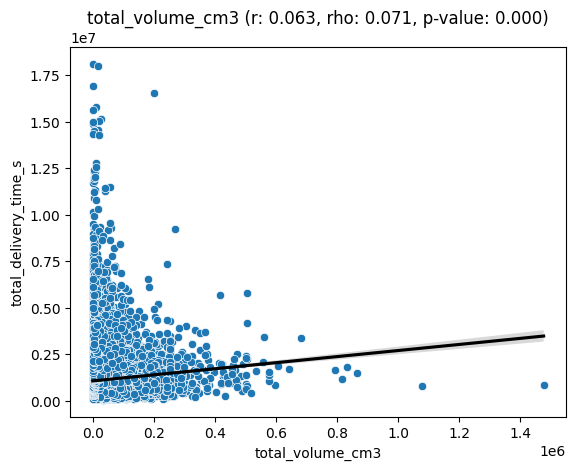

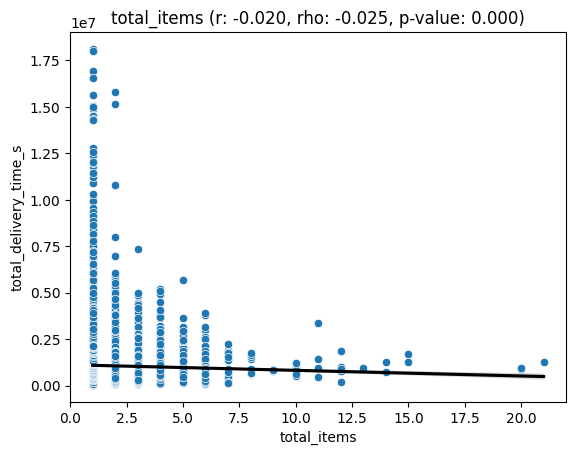

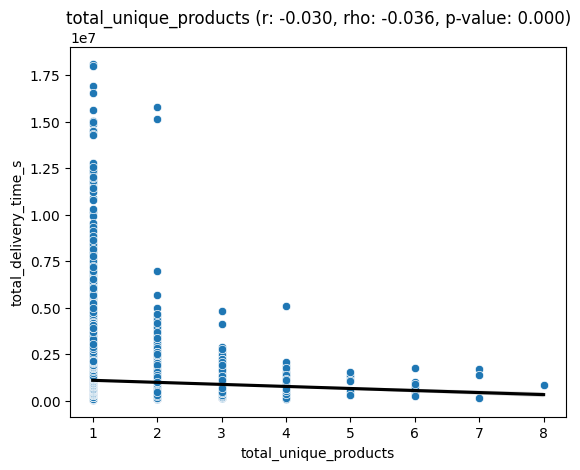

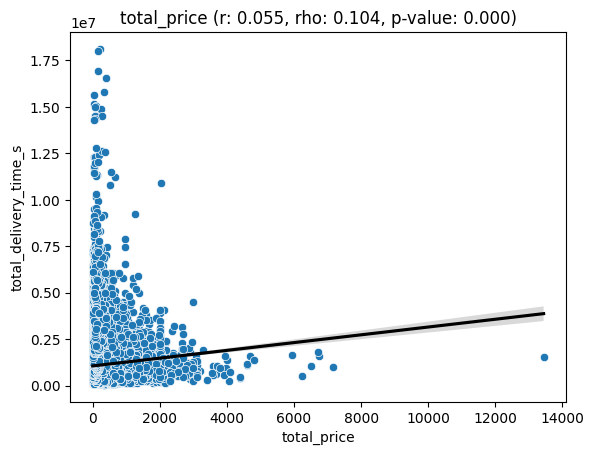

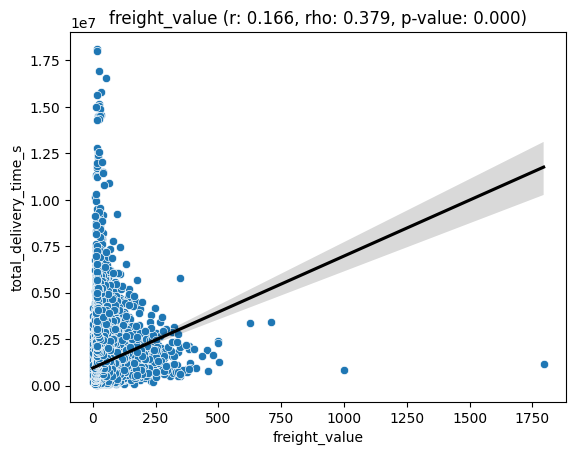

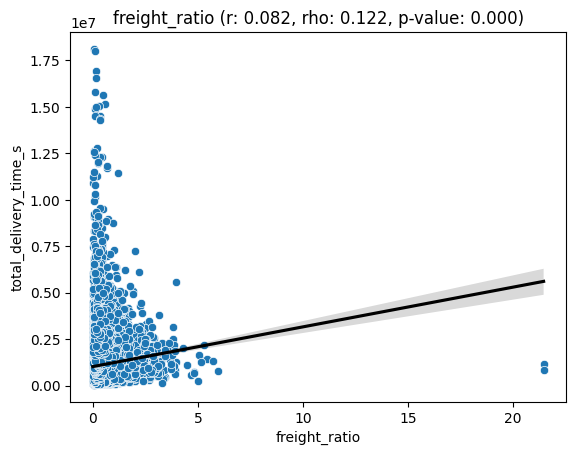

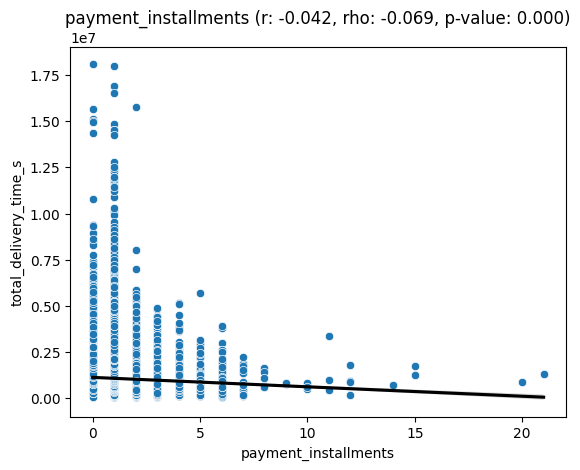

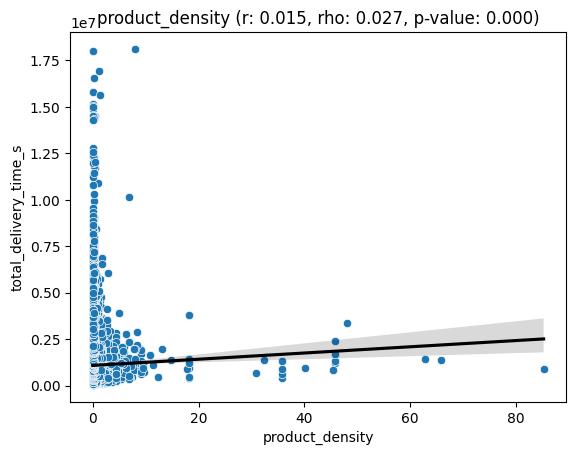

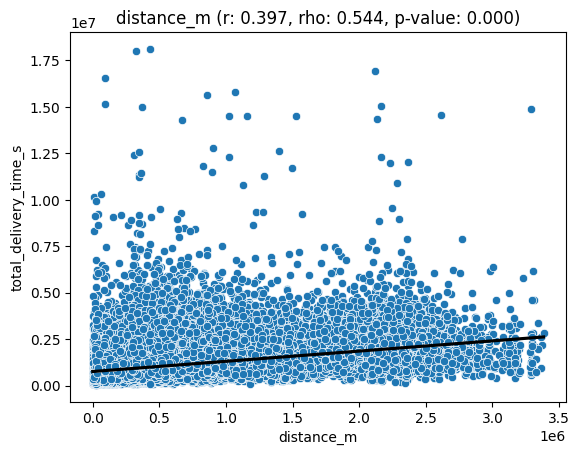

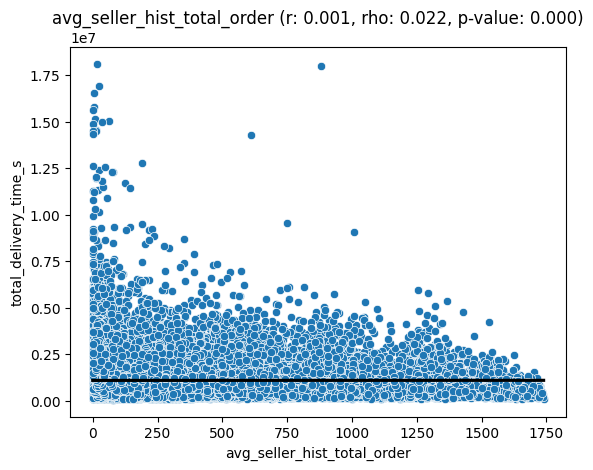

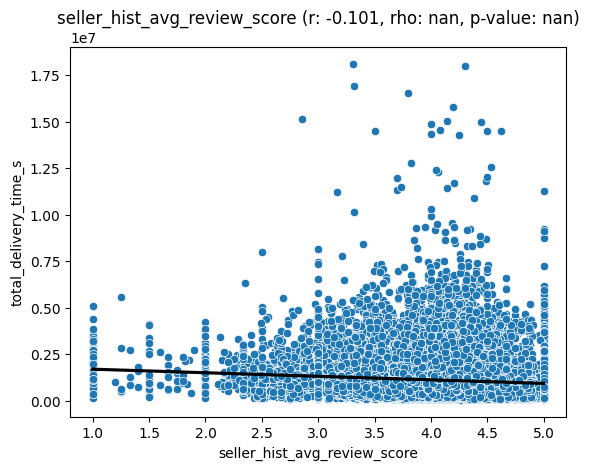

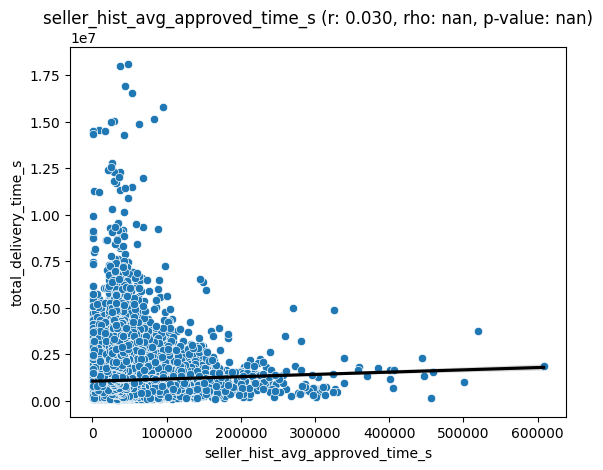

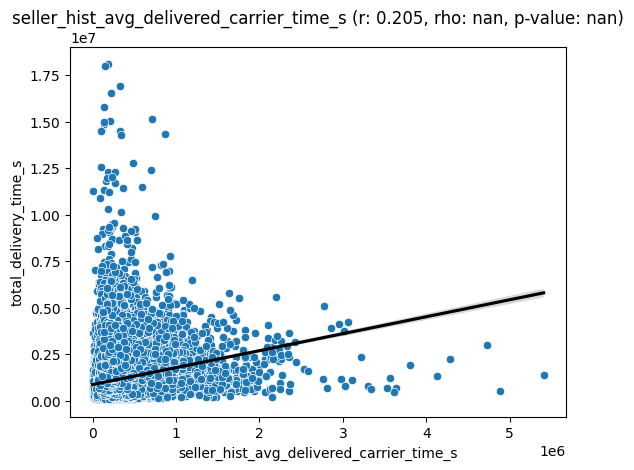

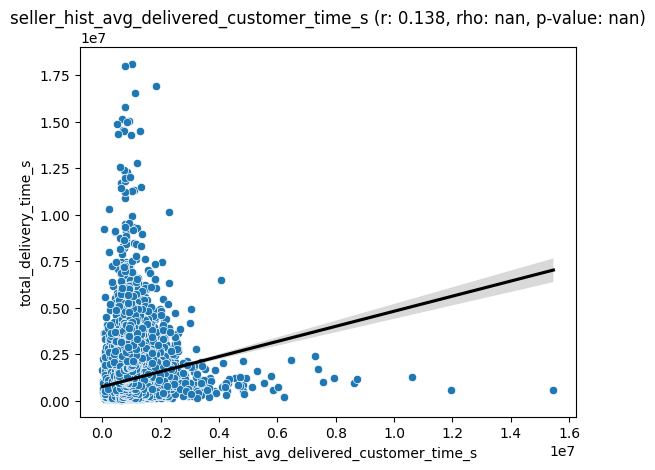

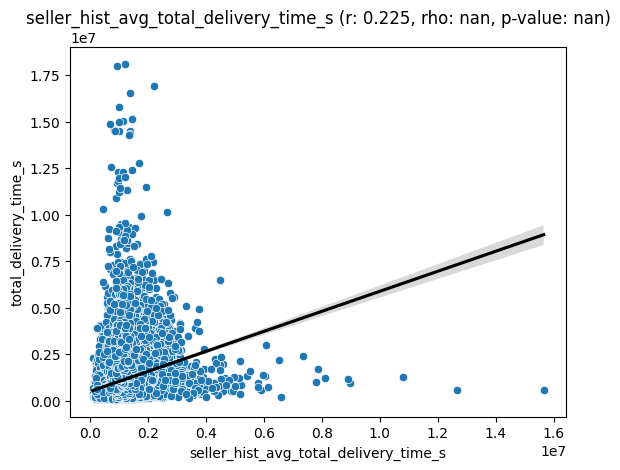

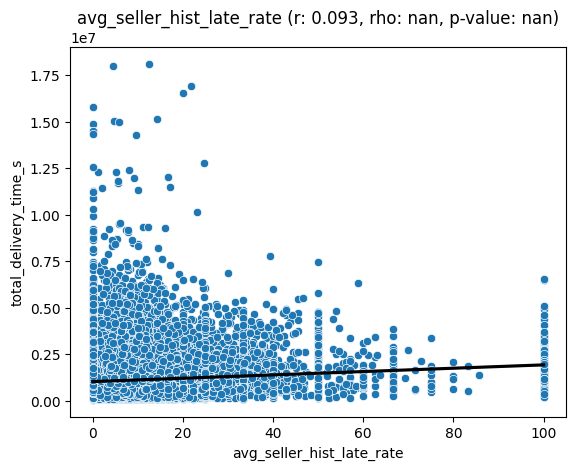

In [45]:
for i in delivery_time_estimation_df.select_dtypes('number'):
    if i not in ['total_delivery_time_s', 'total_estimated_time_s']:
        pearson = delivery_time_estimation_df[i].corr(delivery_time_estimation_df['total_delivery_time_s'])
        rho, p_value = stats.spearmanr(delivery_time_estimation_df[i], delivery_time_estimation_df['total_delivery_time_s'])
        sns.scatterplot(data=delivery_time_estimation_df, x=i, y='total_delivery_time_s')
        sns.regplot(data=delivery_time_estimation_df, x=i, y='total_delivery_time_s', scatter=False, color='black')
        plt.title(f'{i} (r: {pearson:.3f}, rho: {rho:.3f}, p-value: {p_value:.3f})')
        plt.xlabel(i)
        plt.ylabel('total_delivery_time_s')
        plt.show()
        print("="*90)

### Categorical Feature

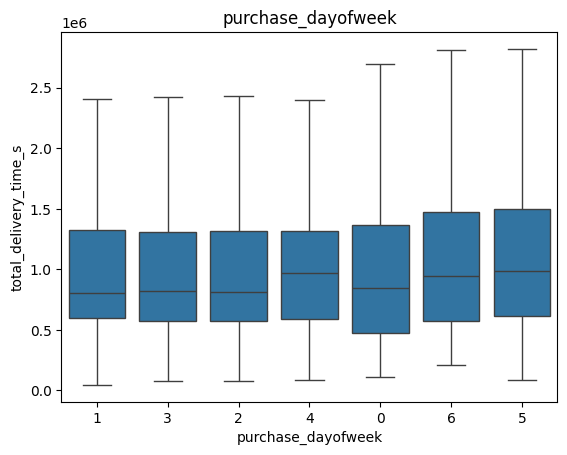

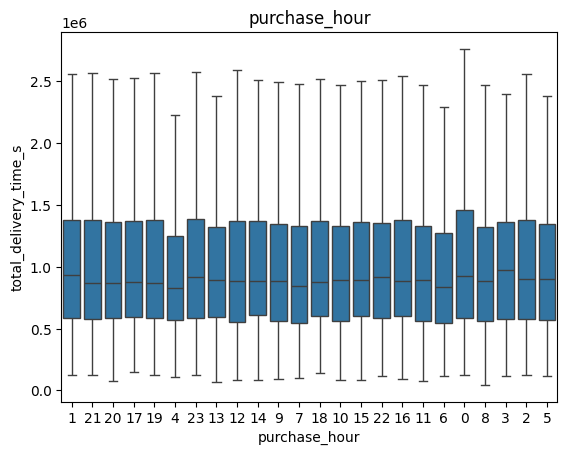

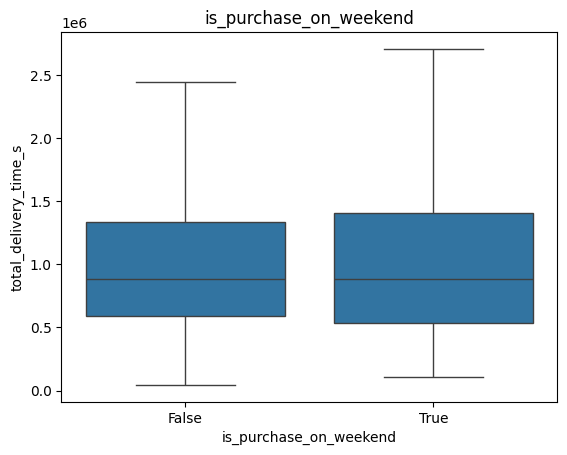

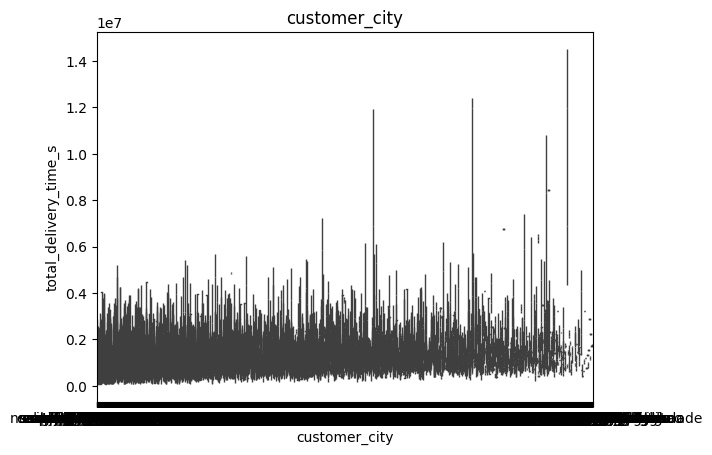

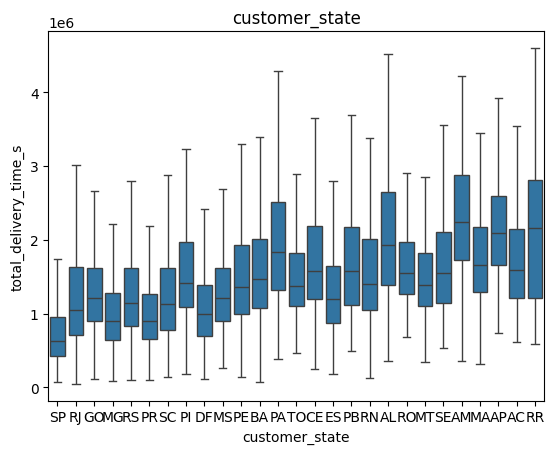

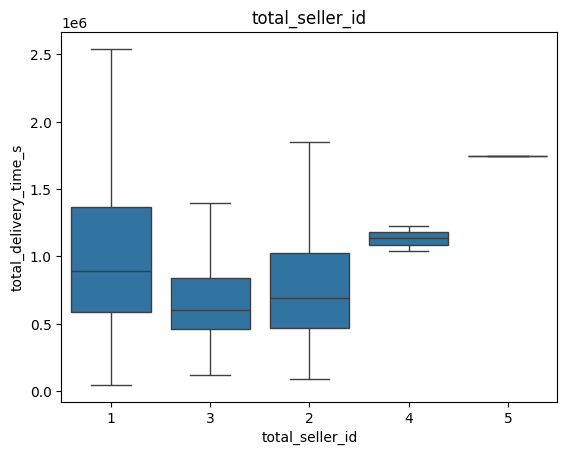

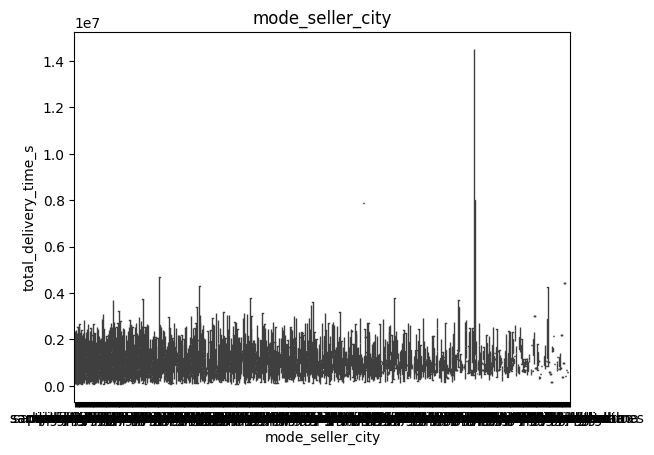

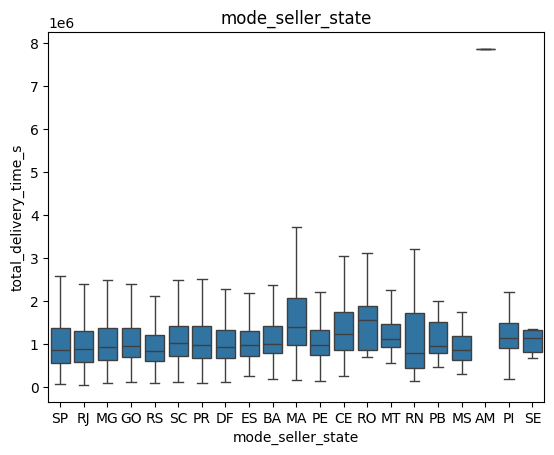

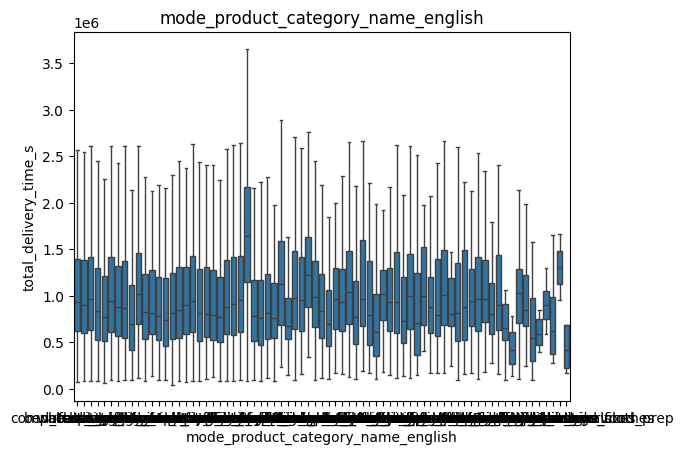

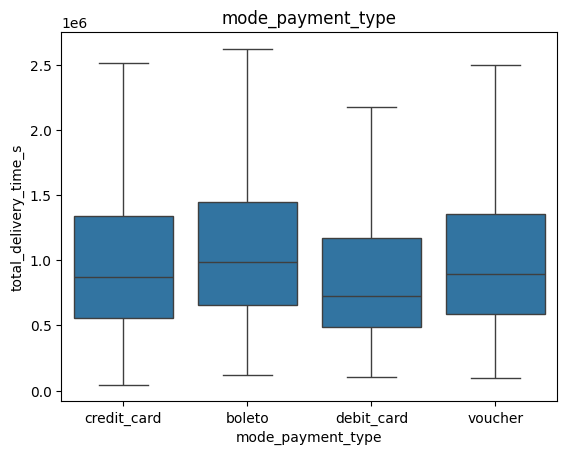

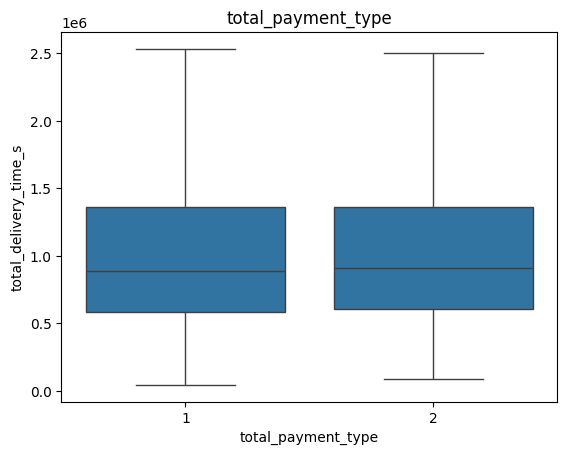

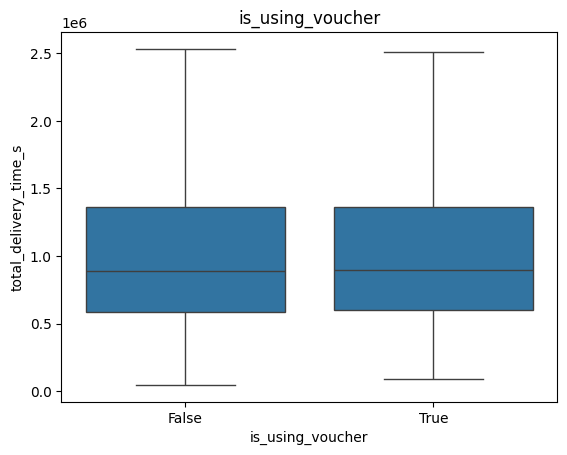

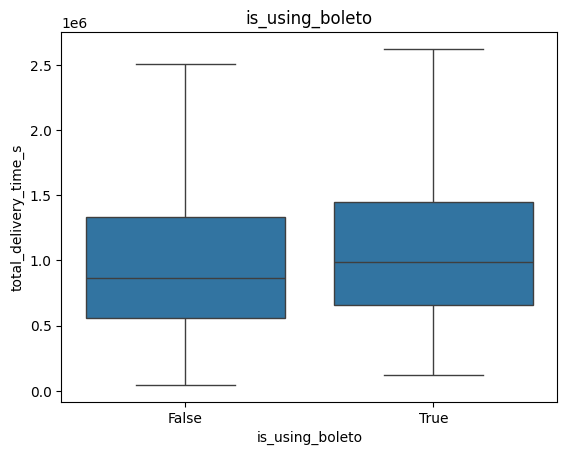

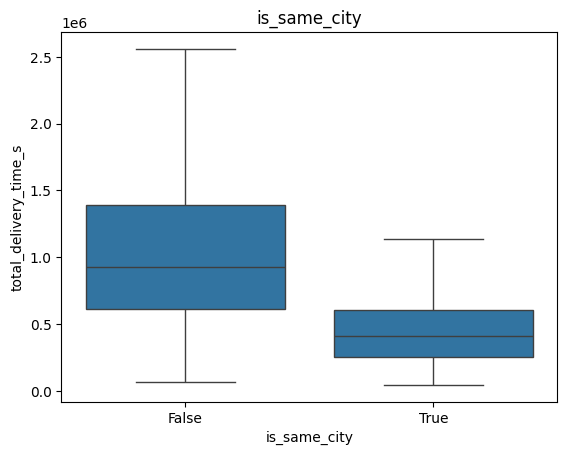

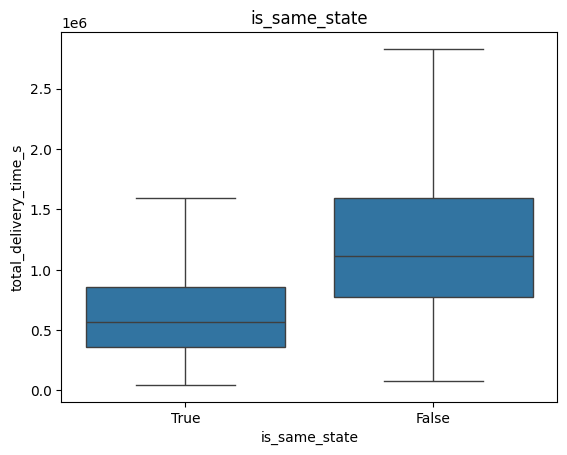

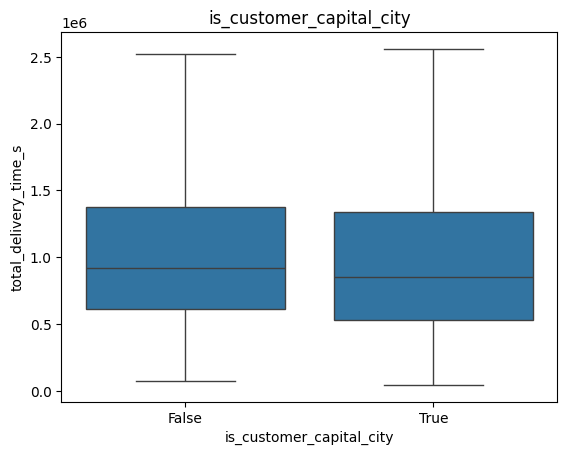

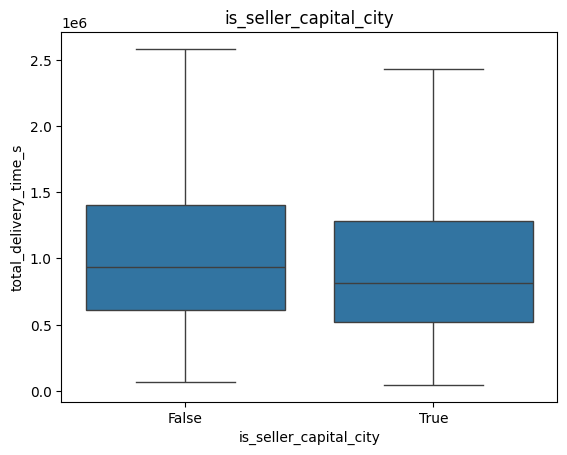

In [46]:
for i in delivery_time_estimation_df.select_dtypes(include=['str']):
    if i not in ['order_id', 'order_status']:
        sns.boxplot(x=i, y='total_delivery_time_s', data=delivery_time_estimation_df, showfliers=False)
        plt.title(f'{i}')
        plt.show()
        print("="*90)

## Features Selection

In [47]:
delivery_time_estimation_df.columns

Index(['order_id', 'total_delivery_time_s', 'total_estimated_time_s',
       'order_status', 'purchase_dayofweek', 'purchase_hour',
       'is_purchase_on_weekend', 'customer_city', 'customer_state',
       'total_seller_id', 'seller_avg_review_score', 'mode_seller_city',
       'mode_seller_state', 'mode_product_category_name_english',
       'total_weight_g', 'total_volume_cm3', 'total_items',
       'total_unique_products', 'total_price', 'freight_value',
       'freight_ratio', 'payment_installments', 'mode_payment_type',
       'total_payment_type', 'is_using_voucher', 'is_using_boleto',
       'product_density', 'distance_m', 'is_same_city', 'is_same_state',
       'is_customer_capital_city', 'is_seller_capital_city',
       'avg_seller_hist_total_order', 'seller_hist_avg_review_score',
       'seller_hist_avg_approved_time_s',
       'seller_hist_avg_delivered_carrier_time_s',
       'seller_hist_avg_delivered_customer_time_s',
       'seller_hist_avg_total_delivery_time_s', 'av

In [48]:
selected_features = ['total_weight_g', 'total_volume_cm3', 'freight_value', 'freight_ratio', 'distance_m', 'seller_hist_avg_review_score', 'seller_hist_avg_delivered_carrier_time_s', 'seller_hist_avg_delivered_customer_time_s', 'seller_hist_avg_total_delivery_time_s', 'avg_seller_hist_late_rate', 'customer_state',  'is_same_city', 'is_same_state']

selected_features_df = delivery_time_estimation_df[selected_features]
selected_features_df

,total_weight_g,total_volume_cm3,freight_value,freight_ratio,distance_m,seller_hist_avg_review_score,seller_hist_avg_delivered_carrier_time_s,seller_hist_avg_delivered_customer_time_s,seller_hist_avg_total_delivery_time_s,avg_seller_hist_late_rate,customer_state,is_same_city,is_same_state
0,2600.0,7616.0,11.90,0.103568,190865.581,4.143415,196141.023301,8.140858e+05,1.047966e+06,7.961165,SP,False,True
1,250.0,640.0,7.60,0.155102,22744.726,3.976558,109624.320466,7.093702e+05,8.519849e+05,6.372549,SP,True,True
2,250.0,1235.0,7.39,0.434962,15811.099,4.242188,127811.232558,7.819479e+05,9.467023e+05,9.302326,SP,True,True
3,50.0,5625.0,8.88,0.042488,13394.809,3.977778,147291.152174,1.114032e+06,1.286636e+06,15.217391,RJ,True,True
4,250.0,2880.0,7.39,0.388947,9475.574,4.200165,150853.996713,7.502082e+05,9.429082e+05,8.052588,SP,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
92067,350.0,816.0,14.10,0.564226,489745.660,4.033632,282562.391982,8.519193e+05,1.179485e+06,8.685969,MG,False,False
92068,1225.0,19950.0,17.95,0.179680,586885.223,3.875000,243340.093750,1.057291e+06,1.310793e+06,15.625000,RJ,False,False
92069,167.0,528.0,16.98,0.220519,1400471.506,4.035433,306270.264591,8.893539e+05,1.235705e+06,7.003891,BA,False,False
92070,16133.0,92925.0,64.88,0.360645,2064989.171,3.461310,950538.736655,9.265535e+05,1.922368e+06,9.964413,PI,False,False


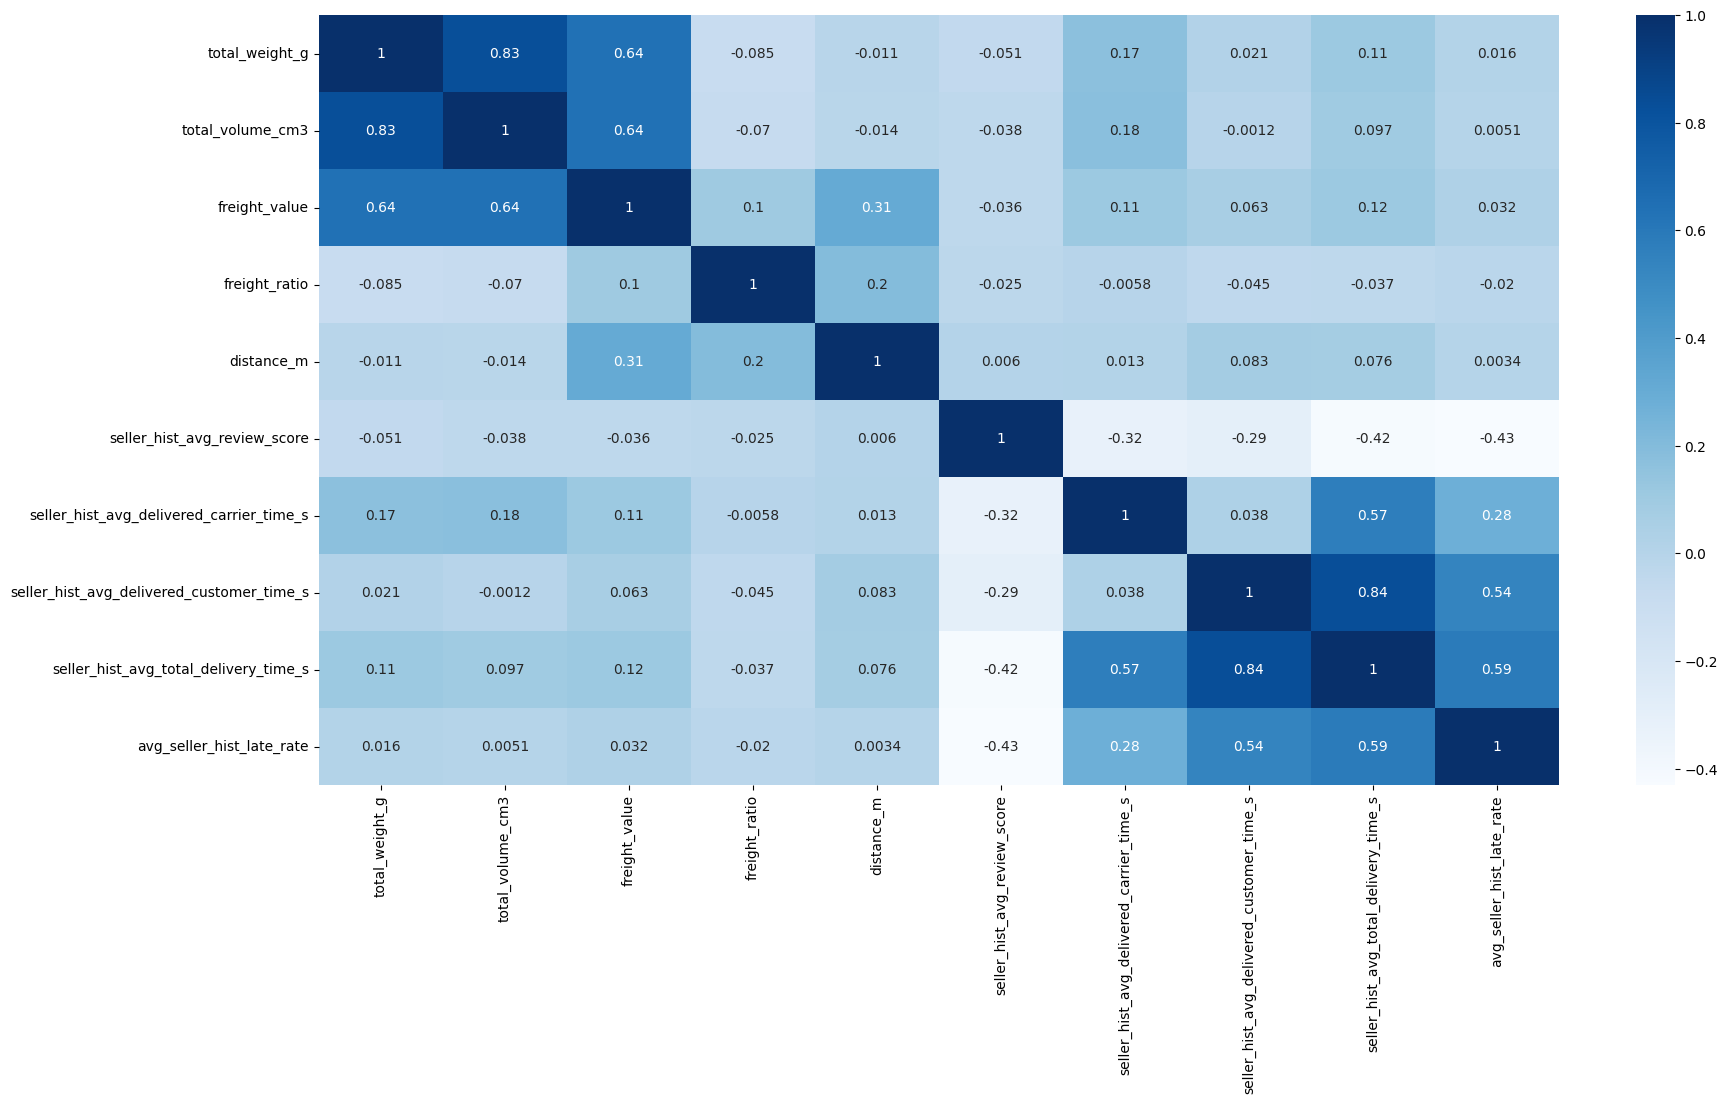

In [49]:
plt.figure(figsize=(20,10))
sns.heatmap(selected_features_df.select_dtypes('number').corr(),annot=True,cmap='Blues')
plt.show()

## Split Train and Test

In [50]:
X = delivery_time_estimation_df[selected_features_df.columns]
X

,total_weight_g,total_volume_cm3,freight_value,freight_ratio,distance_m,seller_hist_avg_review_score,seller_hist_avg_delivered_carrier_time_s,seller_hist_avg_delivered_customer_time_s,seller_hist_avg_total_delivery_time_s,avg_seller_hist_late_rate,customer_state,is_same_city,is_same_state
0,2600.0,7616.0,11.90,0.103568,190865.581,4.143415,196141.023301,8.140858e+05,1.047966e+06,7.961165,SP,False,True
1,250.0,640.0,7.60,0.155102,22744.726,3.976558,109624.320466,7.093702e+05,8.519849e+05,6.372549,SP,True,True
2,250.0,1235.0,7.39,0.434962,15811.099,4.242188,127811.232558,7.819479e+05,9.467023e+05,9.302326,SP,True,True
3,50.0,5625.0,8.88,0.042488,13394.809,3.977778,147291.152174,1.114032e+06,1.286636e+06,15.217391,RJ,True,True
4,250.0,2880.0,7.39,0.388947,9475.574,4.200165,150853.996713,7.502082e+05,9.429082e+05,8.052588,SP,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
92067,350.0,816.0,14.10,0.564226,489745.660,4.033632,282562.391982,8.519193e+05,1.179485e+06,8.685969,MG,False,False
92068,1225.0,19950.0,17.95,0.179680,586885.223,3.875000,243340.093750,1.057291e+06,1.310793e+06,15.625000,RJ,False,False
92069,167.0,528.0,16.98,0.220519,1400471.506,4.035433,306270.264591,8.893539e+05,1.235705e+06,7.003891,BA,False,False
92070,16133.0,92925.0,64.88,0.360645,2064989.171,3.461310,950538.736655,9.265535e+05,1.922368e+06,9.964413,PI,False,False


In [51]:
target = 'total_delivery_time_s'
y = delivery_time_estimation_df[target]
y

0         153468
1         167735
2         170712
3         171215
4         176339
          ...   
92067    2123908
92068    2129658
92069    2895003
92070    3919682
92071    3058979
Name: total_delivery_time_s, Length: 92072, dtype: int64

In [52]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

for i in [X_train, X_test, y_train, y_test]:
    print(i.shape)

(73657, 13)
(18415, 13)
(73657,)
(18415,)


## Feature Engineering

In [53]:
preprocessor = ColumnTransformer(
    transformers=[
        ('Categorical', Pipeline([
            ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore'))
        ]), X_train.select_dtypes(include=['str']).columns)
        ,
        ('Numerical', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', RobustScaler())
        ]), X_train.select_dtypes(include=['float64']).columns)
    ],
    remainder='passthrough',
    verbose_feature_names_out=False
)

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Categorical', ...), ('Numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features

## Modeling

In [54]:
models = {
    'LinearRegression'  : LinearRegression(),
    'Ridge'             : Ridge(random_state=42),
    'Lasso'             : Lasso(random_state=42),
    'ElasticNet'        : ElasticNet(random_state=42),
    'KNN'               : KNeighborsRegressor(),
    'DecisionTree'      : DecisionTreeRegressor(random_state=42),
    'RandomForest'      : RandomForestRegressor(random_state=42),
    'GradientBoosting'  : GradientBoostingRegressor(random_state=42),
    'HistGB'            : HistGradientBoostingRegressor(random_state=42),
    'Bagging'           : BaggingRegressor(random_state=42),
    'AdaBoost'          : AdaBoostRegressor(random_state=42),
    'XGBoost'           : XGBRegressor(random_state=42),
    'LightGBM'          : LGBMRegressor(random_state=42, force_row_wise=True, verbosity=-1)
}

scoring = {
    'R2':    'r2',
    'MAE':   'neg_mean_absolute_error',
    'MedAE': 'neg_median_absolute_error'
}


results = []
with warnings.catch_warnings():
    warnings.simplefilter('ignore')

    for name, model in tqdm(models.items(), total=len(models), desc='Base Model: '):
        pipe = Pipeline([('prep', preprocessor), ('model', model)])
        cv = cross_validate(pipe, X_train, y_train, cv=5, scoring=scoring, return_train_score=True)

        results.append({
            'Model'              : name,

            'Mean Train MAE'     : (-cv['train_MAE'].mean()/86400).round(3),
            'Mean Test MAE'      : (-cv['test_MAE'].mean()/86400).round(3),
            'Diff Mean MAE'      : ((-cv['train_MAE'].mean()/86400) - (-cv['test_MAE'].mean())/86400).round(3),

            'Mean Train MedAE'   : (-cv['train_MedAE'].mean()/86400).round(3),
            'Mean Test MedAE'    : (-cv['test_MedAE'].mean()/86400).round(3),
            'Diff Mean MedAE'    : ((-cv['train_MedAE'].mean()/86400) - (-cv['test_MedAE'].mean()/86400)).round(3),

            'Mean Train R2'      : cv['train_R2'].mean().round(3),
            'Mean Test R2'       : cv['test_R2'].mean().round(3),
            'Diff Mean R2'       : (cv['train_R2'].mean() - cv['test_R2'].mean()).round(3)
        })

base_model_df = pd.DataFrame(results).sort_values('Mean Test MAE', ascending=True)
base_model_df

Base Model: 100%|██████████| 13/13 [05:51<00:00, 27.00s/it]


,Model,Mean Train MAE,Mean Test MAE,Diff Mean MAE,Mean Train MedAE,Mean Test MedAE,Diff Mean MedAE,Mean Train R2,Mean Test R2,Diff Mean R2
12,LightGBM,4.739,4.935,-0.196,3.365,3.442,-0.077,0.366,0.294,0.072
8,HistGB,4.769,4.943,-0.174,3.372,3.450,-0.078,0.356,0.293,0.063
11,XGBoost,4.269,4.989,-0.720,3.054,3.403,-0.349,0.524,0.271,0.253
7,GradientBoosting,4.950,5.005,-0.055,3.520,3.542,-0.022,0.308,0.278,0.030
6,RandomForest,1.878,5.054,-3.176,1.279,3.500,-2.221,0.898,0.273,0.625
0,LinearRegression,5.105,5.110,-0.005,3.677,3.684,-0.008,0.264,0.262,0.002
1,Ridge,5.105,5.110,-0.005,3.677,3.684,-0.007,0.264,0.262,0.002
2,Lasso,5.105,5.110,-0.005,3.677,3.684,-0.007,0.264,0.262,0.002
3,ElasticNet,5.316,5.317,-0.001,4.038,4.036,0.002,0.224,0.224,0.000
9,Bagging,2.104,5.319,-3.215,1.256,3.586,-2.330,0.856,0.205,0.652


Selected Base Model that will be processed to Hyperparameter Tuning (Criteria: Low MAE and does not overfiting between train and test):
- LightGBM,
- HistGB,
- GradientBoosting,
- Lasso,
- Ridge,
- LinearRegression,
- ElasticNet

## Hyperparameter Tuning

In [55]:
tuning_configs = {
    'LightGBM': {
        'model': LGBMRegressor(random_state=42, force_row_wise=True, verbosity=-1),
        'params': {
            'model__n_estimators': [150, 250],
            'model__learning_rate': [0.03, 0.08],
            'model__num_leaves': [25, 45],   
            'model__colsample_bytree': [0.8, 1.0],
            'model__reg_alpha': [0.01, 1.0]
        }
    },
    'HistGB': {
        'model': HistGradientBoostingRegressor(random_state=42),
        'params': {
            'model__max_iter': [150, 250],          
            'model__learning_rate': [0.03, 0.08],
            'model__max_leaf_nodes': [25, 45],       
            'model__l2_regularization': [0.0, 1.0]
        }
    }, 
    'GradientBoosting': {
        'model': GradientBoostingRegressor(random_state=42),
        'params': {
            'model__n_estimators': [100, 200],
            'model__learning_rate': [0.05, 0.1],
            'model__max_depth': [3, 5],
            'model__subsample': [0.8, 1.0]
        }
    }, 
    'LinearRegression': {
        'model': LinearRegression(),
        'params': {
            'model__fit_intercept': [True, False]
        }
    },
    'Ridge': {
        'model': Ridge(random_state=42),
        'params': {
            'model__alpha': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]
        }
    },
    'Lasso': {
        'model': Lasso(random_state=42, max_iter=5000),
        'params': {
            'model__alpha': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
        }
    },
    'ElasticNet': {
        'model': ElasticNet(random_state=42, max_iter=5000),
        'params': {
            'model__alpha': [0.001, 0.01, 0.1, 1.0, 10.0],
            'model__l1_ratio': [0.2, 0.5, 0.7, 0.9]
        }
    }
}

results = []
best_estimators = {}

with warnings.catch_warnings():
    warnings.simplefilter('ignore')

    for name, config in tqdm(tuning_configs.items(), desc='Hyperparameter Tuning: '):
        pipe = Pipeline([
            ('prep', preprocessor), 
            ('model', config['model'])
        ])

        gscv = GridSearchCV(
            estimator=pipe,
            param_grid=config['params'],
            scoring='neg_mean_absolute_error',
            cv=5,
            n_jobs=-1,
            return_train_score=True
        )
        
        gscv.fit(X_train, y_train)

        best_estimators[name] = gscv.best_estimator_

        results.append({
            'Model': name,
            'Best Test MAE': round((-gscv.best_score_/86400), 3),
            'Best Params': gscv.best_params_
        })

tuning_df = pd.DataFrame(results).sort_values('Best Test MAE', ascending=True)
tuning_df

Hyperparameter Tuning: 100%|██████████| 7/7 [10:34<00:00, 90.67s/it] 


,Model,Best Test MAE,Best Params
0,LightGBM,4.901,"{'model__colsample_bytree': 0.8, 'model__learn..."
1,HistGB,4.928,"{'model__l2_regularization': 0.0, 'model__lear..."
2,GradientBoosting,4.966,"{'model__learning_rate': 0.1, 'model__max_dept..."
3,LinearRegression,5.110,{'model__fit_intercept': True}
4,Ridge,5.110,{'model__alpha': 10.0}
5,Lasso,5.110,{'model__alpha': 100.0}
6,ElasticNet,5.110,"{'model__alpha': 0.001, 'model__l1_ratio': 0.7}"


## Predict with Best Model

In [61]:
gscv = GridSearchCV(
            estimator=Pipeline([('prep', preprocessor), ('model', tuning_configs['LightGBM']['model'])]),
            param_grid={'model__colsample_bytree': [0.8], 'model__learning_rate': [0.08], 'model__n_estimators': [250], 'model__num_leaves': [45], 'model__reg_alpha': [0.01]},
            scoring='neg_mean_absolute_error',
            cv=5,
            n_jobs=-1,
            return_train_score=True
        )

gscv.fit(X_train, y_train)

best_model = gscv.best_estimator_
best_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['total_weight_g','total_volume_cm3','freight_value',...,'customer_state', 'is_same_city','is_same_state']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Categorical', ...), ('Numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatical

In [62]:
best_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['total_weight_g','total_volume_cm3','freight_value',...,'customer_state', 'is_same_city','is_same_state']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Categorical', ...), ('Numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatical

In [63]:
y_pred = best_model.predict(X_test)

## Model Evaluation

In [64]:
y_pred_index = pd.Series(y_pred, index=X_test.index)
y_estimated_ori = delivery_time_estimation_df['total_estimated_time_s'].loc[y_test.index]

In [65]:
y_list = {
    'y_test_days'        : y_test,
    'y_pred_days'        : y_pred_index,
    'y_estimated_days'   : y_estimated_ori
}

dfs = {}
for name, series in y_list.items():
    dfs[name] = (series / 86400).rename('total_delivery_days')

globals().update(dfs)

In [66]:
y_combine = pd.DataFrame({
    'y_test_days': y_test_days,
    'y_estimated_days': y_estimated_days,
    'y_pred_days': y_pred_days
})

y_combine

,y_test_days,y_estimated_days,y_pred_days
56917,22.500509,35.974745,18.129060
83056,7.487998,17.025718,11.447554
41431,10.130995,24.110972,14.410597
87068,5.691493,12.124155,4.338388
57551,14.877650,42.050613,19.981487
...,...,...,...
82359,28.542708,20.989502,15.053489
79427,14.978727,22.000197,14.419579
75869,7.901227,30.083356,8.584368
65684,2.896644,14.371100,4.376400


In [67]:
query = """
SELECT 
    AVG(ABS(y_test_days - y_estimated_days)) AS mae_estimated_by_olist,
    AVG(ABS(y_test_days - y_pred_days)) AS mae_model_prediction,
    ROUND(
        (AVG(ABS(y_test_days - y_estimated_days)) - AVG(ABS(y_test_days - y_pred_days))) 
        / AVG(ABS(y_test_days - y_estimated_days)) * 100, 
        2
    ) AS pct_improvement
FROM y_combine
"""

model_evaluation = duckdb.sql(query).to_df()
model_evaluation

,mae_estimated_by_olist,mae_model_prediction,pct_improvement
0,12.708313,4.866304,61.71


The machine learning model reduced the average estimation error from 12.7 days down to 4.87 days, making delivery date predictions **61.71% more accurate** and cutting estimation discrepancies by nearly 7 days on average

## Features Importance

In [68]:
raw_importances = pd.Series(
    best_model.named_steps['model'].feature_importances_,
    index=best_model.named_steps['prep'].get_feature_names_out()
)

normalized_importances = raw_importances / raw_importances.sum()

normalized_df = pd.DataFrame({
    'Feature': normalized_importances.index,
    'Importance': normalized_importances.values.round(4)
}).sort_values('Importance', ascending=False).reset_index(drop=True)

normalized_df

,Feature,Importance
0,seller_hist_avg_delivered_carrier_time_s,0.1204
1,distance_m,0.0992
2,freight_value,0.0963
3,freight_ratio,0.0932
4,seller_hist_avg_review_score,0.0917
5,seller_hist_avg_total_delivery_time_s,0.0863
6,seller_hist_avg_delivered_customer_time_s,0.0854
7,total_volume_cm3,0.0822
8,avg_seller_hist_late_rate,0.0817
9,total_weight_g,0.0789


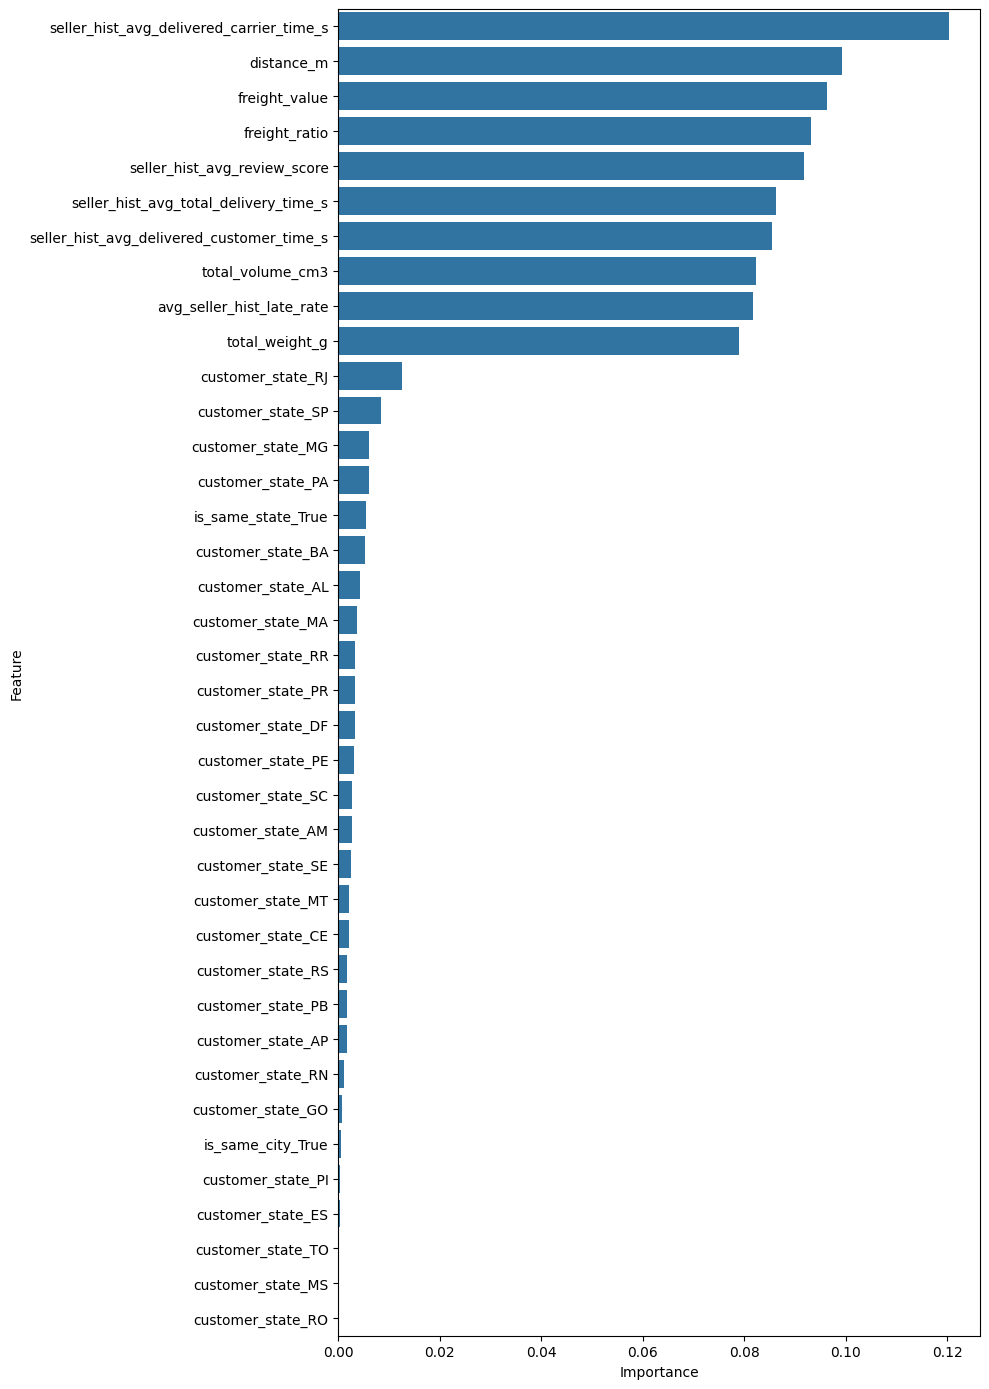

In [69]:
plt.figure(figsize=(10, 14))

# 2. Draw the barplot
ax = sns.barplot(
    data=normalized_df, 
    x='Importance', 
    y='Feature'
)

plt.tight_layout()
plt.show()

## Save Model

In [70]:
pickle.dump(best_model, open('model_delivery_time_prediction.sav', 'wb'))